# Fuzzy Logic Control System for Fan Speed

This notebook demonstrates the implementation of a fuzzy logic control system to determine the optimal fan speed based on ambient temperature and humidity. The system uses `scikit-fuzzy` to define linguistic variables, membership functions, and fuzzy rules, ultimately performing fuzzy inference to suggest a fan speed.

**Outline:**
1.  **Dependencies Installation & Imports:** Setting up the necessary libraries.
2.  **Define Linguistic Variables:** Temperature, Humidity, and Fan Speed as fuzzy sets.
3.  **Membership Functions:** Defining the ranges and shapes for 'cold', 'warm', 'hot', 'low', 'medium', 'high' for each variable.
4.  **Fuzzy Rules:** Establishing the 'if-then' conditions that govern the fan's behavior.
5.  **Control System & Simulation:** Creating and running the fuzzy inference engine.
6.  **Test Cases:** Evaluating the system with various temperature and humidity inputs.
7.  **Fuzzification Analysis:** Detailed breakdown of how input values map to membership degrees.
8.  **Visualization:** Plotting the membership functions for better understanding.

In [ ]:
!pip install scikit-fuzzy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 920.8/920.8 kB 15.3 MB/s eta 0:00:00


## 1. Dependencies Installation & Imports

First, we install the `scikit-fuzzy` library and import all necessary modules.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl

## 2. Define Linguistic Variables

Here, we define the fuzzy sets for `temperature`, `humidity`, and `fan_speed` using `ctrl.Antecedent` and `ctrl.Consequent` respectively. Each variable has a universe of discourse, which is the range of possible values it can take.

In [ ]:
temperature = ctrl.Antecedent(np.arange(0, 51, 1), 'temperature')

humidity = ctrl.Antecedent(np.arange(0, 101, 1), 'humidity')

fan_speed = ctrl.Consequent(np.arange(0, 101, 1), 'fan_speed')

## 3. Membership Functions

Next, we define the membership functions for each linguistic variable. These functions map a crisp input value to a degree of membership (between 0 and 1) in a fuzzy set (e.g., 'cold', 'warm', 'hot'). We use triangular membership functions (`fuzz.trimf`) for simplicity.

In [ ]:
# Temperature Membership Functions
temperature['cold'] = fuzz.trimf(
    temperature.universe,
    [0, 0, 25]
)

temperature['warm'] = fuzz.trimf(
    temperature.universe,
    [15, 25, 35]
)

temperature['hot'] = fuzz.trimf(
    temperature.universe,
    [25, 50, 50]
)


# Humidity Membership Functions
humidity['low'] = fuzz.trimf(
    humidity.universe,
    [0, 0, 50]
)

humidity['medium'] = fuzz.trimf(
    humidity.universe,
    [25, 50, 75]
)

humidity['high'] = fuzz.trimf(
    humidity.universe,
    [50, 100, 100]
)


# Fan Speed Membership Functions
fan_speed['low'] = fuzz.trimf(
    fan_speed.universe,
    [0, 0, 50]
)

fan_speed['medium'] = fuzz.trimf(
    fan_speed.universe,
    [25, 50, 75]
)

fan_speed['high'] = fuzz.trimf(
    fan_speed.universe,
    [50, 100, 100]
)

## 4. Fuzzy Rules

Fuzzy rules are 'if-then' statements that connect the antecedent (input) variables to the consequent (output) variable. These rules capture the expert knowledge about how fan speed should change based on temperature and humidity.

In [ ]:
# Fuzzy Rules

rule1 = ctrl.Rule(
    temperature['cold'] & humidity['low'],
    fan_speed['low']
)

rule2 = ctrl.Rule(
    temperature['cold'] & humidity['medium'],
    fan_speed['low']
)

rule3 = ctrl.Rule(
    temperature['cold'] & humidity['high'],
    fan_speed['medium']
)

rule4 = ctrl.Rule(
    temperature['warm'] & humidity['low'],
    fan_speed['low']
)

rule5 = ctrl.Rule(
    temperature['warm'] & humidity['medium'],
    fan_speed['medium']
)

rule6 = ctrl.Rule(
    temperature['warm'] & humidity['high'],
    fan_speed['high']
)

rule7 = ctrl.Rule(
    temperature['hot'] & humidity['low'],
    fan_speed['medium']
)

rule8 = ctrl.Rule(
    temperature['hot'] & humidity['medium'],
    fan_speed['high']
)

rule9 = ctrl.Rule(
    temperature['hot'] & humidity['high'],
    fan_speed['high']
)

## 5. Control System & Simulation

We combine the defined rules into a `ctrl.ControlSystem` and then create a `ctrl.ControlSystemSimulation` object to run the fuzzy inference process. This simulation object allows us to input crisp values for temperature and humidity and obtain a crisp output for fan speed.

In [ ]:
# Create the fuzzy control system

fan_control = ctrl.ControlSystem([
    rule1, rule2, rule3,
    rule4, rule5, rule6,
    rule7, rule8, rule9
])

fan_simulation = ctrl.ControlSystemSimulation(
    fan_control
)

## 6. Test Cases

We define several test cases to evaluate the fuzzy control system. For each test case, we provide specific temperature and humidity values, and the system computes the recommended fan speed. The output is then interpreted into low, medium, or high fan speed levels.

In [ ]:
# Test cases: Temperature and Humidity

test_cases = [
    (10, 20),
    (20, 60),
    (25, 50),
    (30, 70),
    (40, 90)
]

print("================================================")
print("TEMPERATURE AND HUMIDITY FUZZY CONTROL SYSTEM")
print("================================================")

for temp, hum in test_cases:

    # Create a fresh simulation for each test case
    simulation = ctrl.ControlSystemSimulation(fan_control)

    # Give inputs
    simulation.input['temperature'] = temp
    simulation.input['humidity'] = hum

    # Perform fuzzy inference
    simulation.compute()

    # Get output
    output_speed = simulation.output['fan_speed']

    print("\nTemperature:", temp, "°C")
    print("Humidity:", hum, "%")
    print("Recommended Fan Speed:", round(output_speed, 2), "%")

    # Interpret output
    if output_speed < 35:
        print("Fan Speed Level: LOW")
    elif output_speed < 70:
        print("Fan Speed Level: MEDIUM")
    else:
        print("Fan Speed Level: HIGH")

TEMPERATURE AND HUMIDITY FUZZY CONTROL SYSTEM

Temperature: 10 °C
Humidity: 20 %
Recommended Fan Speed: 18.57 %
Fan Speed Level: LOW

Temperature: 20 °C
Humidity: 60 %
Recommended Fan Speed: 50.0 %
Fan Speed Level: MEDIUM

Temperature: 25 °C
Humidity: 50 %
Recommended Fan Speed: 50.0 %
Fan Speed Level: MEDIUM

Temperature: 30 °C
Humidity: 70 %
Recommended Fan Speed: 69.81 %
Fan Speed Level: MEDIUM

Temperature: 40 °C
Humidity: 90 %
Recommended Fan Speed: 81.43 %
Fan Speed Level: HIGH


## 7. Fuzzification Analysis

This section delves deeper into the fuzzification process. For each test case, it calculates the degree of membership of the given temperature and humidity values in their respective fuzzy sets (e.g., how 'cold' a temperature of 10°C is). This helps in understanding how the inputs contribute to the activation of different fuzzy rules.

In [ ]:
print("======================================================")
print("FUZZIFICATION VALUES")
print("======================================================")

for temp, hum in test_cases:

    # Temperature membership values
    temp_cold = fuzz.interp_membership(
        temperature.universe,
        temperature['cold'].mf,
        temp
    )

    temp_warm = fuzz.interp_membership(
        temperature.universe,
        temperature['warm'].mf,
        temp
    )

    temp_hot = fuzz.interp_membership(
        temperature.universe,
        temperature['hot'].mf,
        temp
    )

    # Humidity membership values
    hum_low = fuzz.interp_membership(
        humidity.universe,
        humidity['low'].mf,
        hum
    )

    hum_medium = fuzz.interp_membership(
        humidity.universe,
        humidity['medium'].mf,
        hum
    )

    hum_high = fuzz.interp_membership(
        humidity.universe,
        humidity['high'].mf,
        hum
    )

    print("\n-------------------------------------------")
    print("Temperature:", temp, "°C | Humidity:", hum, "%")

    print("\nTemperature Membership:")
    print("Cold :", round(temp_cold, 3))
    print("Warm :", round(temp_warm, 3))
    print("Hot  :", round(temp_hot, 3))

    print("\nHumidity Membership:")
    print("Low    :", round(hum_low, 3))
    print("Medium :", round(hum_medium, 3))
    print("High   :", round(hum_high, 3))

FUZZIFICATION VALUES

-------------------------------------------
Temperature: 10 °C | Humidity: 20 %

Temperature Membership:
Cold : 0.6
Warm : 0.0
Hot  : 0.0

Humidity Membership:
Low    : 0.6
Medium : 0.0
High   : 0.0

-------------------------------------------
Temperature: 20 °C | Humidity: 60 %

Temperature Membership:
Cold : 0.2
Warm : 0.5
Hot  : 0.0

Humidity Membership:
Low    : 0.0
Medium : 0.6
High   : 0.2

-------------------------------------------
Temperature: 25 °C | Humidity: 50 %

Temperature Membership:
Cold : 0.0
Warm : 1.0
Hot  : 0.0

Humidity Membership:
Low    : 0.0
Medium : 1.0
High   : 0.0

-------------------------------------------
Temperature: 30 °C | Humidity: 70 %

Temperature Membership:
Cold : 0.0
Warm : 0.5
Hot  : 0.2

Humidity Membership:
Low    : 0.0
Medium : 0.2
High   : 0.4

-------------------------------------------
Temperature: 40 °C | Humidity: 90 %

Temperature Membership:
Cold : 0.0
Warm : 0.0
Hot  : 0.6

Humidity Membership:
Low    : 0.0
Mediu

## 8. Visualization of Membership Functions

To better understand how the fuzzy sets are defined, we visualize the membership functions for temperature, humidity, and fan speed. Each plot shows how crisp values map to a degree of membership for 'cold', 'warm', 'hot', 'low', 'medium', and 'high' categories.

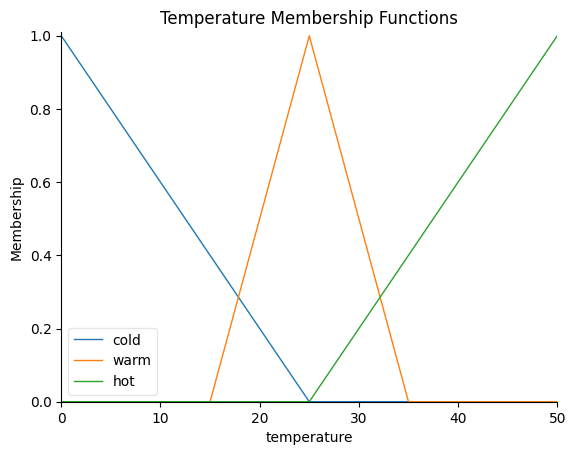

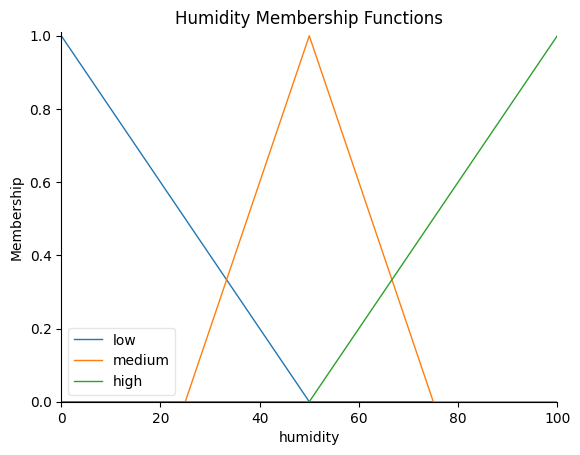

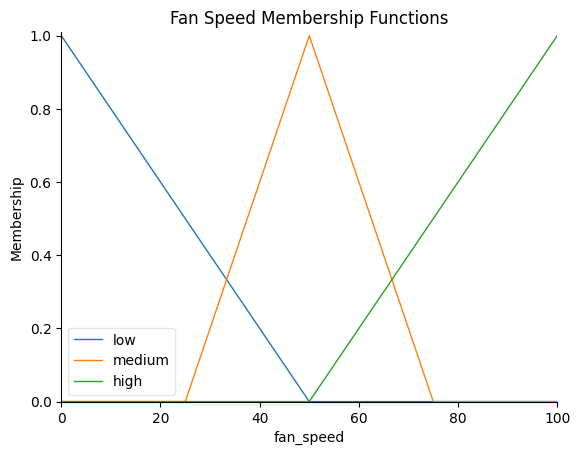

In [ ]:
# Plot Temperature Membership Functions
temperature.view()
plt.title("Temperature Membership Functions")
plt.show()


# Plot Humidity Membership Functions
humidity.view()
plt.title("Humidity Membership Functions")
plt.show()


# Plot Fan Speed Membership Functions
fan_speed.view()
plt.title("Fan Speed Membership Functions")
plt.show()

## Conclusion

This notebook successfully demonstrates the creation and operation of a simple fuzzy logic control system for fan speed. By defining linguistic variables, membership functions, and a set of fuzzy rules, we can effectively map crisp environmental inputs (temperature and humidity) to a crisp output (recommended fan speed) in a human-intuitive way. This approach can be extended to more complex control problems in various domains.